# EDA – PaySim

Objectif : comprendre les données avant de construire le lakehouse et le modèle.

- **PySpark** : calculs sur les 6,3 millions de lignes (chiffres officiels).
- **pandas, numpy, matplotlib** : pratique de l'EDA et graphiques, sur un échantillon de 5 %.

## Sommaire
0. Configuration
1. Chargement et premier aperçu
2. Qualité des données
3. La variable cible
4. Analyse univariée
5. Analyse bivariée
6. Analyse temporelle
7. Corrélations
8. Points spécifiques au projet
9. Conclusions et décisions

## 0. Configuration

Importer les bibliothèques nécessaires 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

Démarrer la session Spark 

In [2]:
spark = (
    SparkSession.builder.master("local[4]")
    .appName("eda-paysim")
    .config("spark.driver.memory", "2g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)
spark.version

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/15 17:33:52 WARN Utils: Your hostname, DESKTOP-MH6TBV3, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/15 17:33:52 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 17:33:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'4.1.3'

In [3]:
# Réglages d'affichage de pandas et matplotlib
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

GRAINE = 42  # graine du hasard, pour des résultats reproductibles

## 1. Chargement et premier aperçu

In [4]:
CHEMIN_CSV = Path("../data/raw/paysim.csv")

schema = T.StructType([
    T.StructField("step", T.IntegerType()),
    T.StructField("type", T.StringType()),
    T.StructField("amount", T.DoubleType()),
    T.StructField("nameOrig", T.StringType()),
    T.StructField("oldbalanceOrg", T.DoubleType()),
    T.StructField("newbalanceOrig", T.DoubleType()),
    T.StructField("nameDest", T.StringType()),
    T.StructField("oldbalanceDest", T.DoubleType()),
    T.StructField("newbalanceDest", T.DoubleType()),
    T.StructField("isFraud", T.IntegerType()),
    T.StructField("isFlaggedFraud", T.IntegerType()),
])

df = spark.read.csv(str(CHEMIN_CSV), header=True, schema=schema)
df.printSchema()
df.show(5)

root
 |-- step: integer (nullable = true)
 |-- type: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- nameOrig: string (nullable = true)
 |-- oldbalanceOrg: double (nullable = true)
 |-- newbalanceOrig: double (nullable = true)
 |-- nameDest: string (nullable = true)
 |-- oldbalanceDest: double (nullable = true)
 |-- newbalanceDest: double (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- isFlaggedFraud: integer (nullable = true)



+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|step|    type|  amount|   nameOrig|oldbalanceOrg|newbalanceOrig|   nameDest|oldbalanceDest|newbalanceDest|isFraud|isFlaggedFraud|
+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+
|   1| PAYMENT| 9839.64|C1231006815|     170136.0|     160296.36|M1979787155|           0.0|           0.0|      0|             0|
|   1| PAYMENT| 1864.28|C1666544295|      21249.0|      19384.72|M2044282225|           0.0|           0.0|      0|             0|
|   1|TRANSFER|   181.0|C1305486145|        181.0|           0.0| C553264065|           0.0|           0.0|      1|             0|
|   1|CASH_OUT|   181.0| C840083671|        181.0|           0.0|  C38997010|       21182.0|           0.0|      1|             0|
|   1| PAYMENT|11668.14|C2048537720|      41554.0|      29885.86|M1230701703|      

In [5]:
nb_lignes = df.count()
print(f"{nb_lignes:,} lignes x {len(df.columns)} colonnes")

6,362,620 lignes x 11 colonnes


In [6]:
echantillon = df.sample(fraction=0.05, seed=GRAINE)
pdf = echantillon.toPandas()
pdf.shape

(318036, 11)

In [23]:
pdf.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"1,563.82",C761750706,450.00,0.00,M1731217984,0.00,0.00,0,0
1,1,TRANSFER,"77,957.68",C207471778,0.00,0.00,C1761291320,"94,900.00","22,233.65",0,0
2,1,TRANSFER,"358,831.92",C908084672,0.00,0.00,C392292416,"474,384.53","3,420,103.09",0,0
3,1,PAYMENT,"1,876.44",C1509309988,182.00,0.00,M1643141512,0.00,0.00,0,0
4,1,CASH_OUT,"14,121.82",C69062746,0.00,0.00,C100555887,"52,679.00","10,963.66",0,0
5,1,PAYMENT,"1,203.44",C922807452,"29,941.00","28,737.56",M33563464,0.00,0.00,0,0
6,1,PAYMENT,"5,213.25",C1221981006,"36,380.00","31,166.75",M264394929,0.00,0.00,0,0
7,1,CASH_OUT,"26,004.52",C1112456099,0.00,0.00,C1225616405,"52,251.58",0.00,0,0
8,1,CASH_OUT,"323,105.08",C1458091526,0.00,0.00,C747464370,"378,299.67","1,567,434.81",0,0
9,1,PAYMENT,"3,930.81",C15477956,"6,032.00","2,101.19",M710623214,0.00,0.00,0,0


In [18]:
pdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 318036 entries, 0 to 318035
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            318036 non-null  int32  
 1   type            318036 non-null  str    
 2   amount          318036 non-null  float64
 3   nameOrig        318036 non-null  str    
 4   oldbalanceOrg   318036 non-null  float64
 5   newbalanceOrig  318036 non-null  float64
 6   nameDest        318036 non-null  str    
 7   oldbalanceDest  318036 non-null  float64
 8   newbalanceDest  318036 non-null  float64
 9   isFraud         318036 non-null  int32  
 10  isFlaggedFraud  318036 non-null  int32  
dtypes: float64(5), int32(3), str(3)
memory usage: 31.7 MB


In [21]:
pdf.describe().T

,count,mean,std,min,25%,50%,75%,max
step,"318,036.00",243.02,142.06,1.00,155.00,239.00,334.00,742.00
amount,"318,036.00","179,120.22","600,264.13",0.00,"13,329.50","74,470.17","208,054.79","53,920,358.88"
oldbalanceOrg,"318,036.00","839,518.78","2,901,612.58",0.00,0.00,"14,183.50","107,497.25","36,149,843.06"
newbalanceOrig,"318,036.00","860,340.98","2,937,312.41",0.00,0.00,0.00,"142,890.65","36,184,717.49"
oldbalanceDest,"318,036.00","1,103,921.65","3,486,023.88",0.00,0.00,"132,801.33","939,408.90","327,998,074.22"
newbalanceDest,"318,036.00","1,227,608.99","3,773,315.84",0.00,0.00,"213,528.42","1,108,597.20","328,431,698.23"
isFraud,"318,036.00",0.00,0.04,0.00,0.00,0.00,0.00,1.00
isFlaggedFraud,"318,036.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [20]:
memoire_mo = pdf.memory_usage(deep=True).sum() / 1024**2
print(f"Mémoire de l'échantillon : {memoire_mo:.1f} Mo")
print(f"Estimation pour le jeu complet : {memoire_mo * 20:,.0f} Mo")

Mémoire de l'échantillon : 31.7 Mo
Estimation pour le jeu complet : 633 Mo


### Constats – partie 1
- pas de valeurs manquantes et types cohérents dans cet échantillon
- pour amout : moyenne est deux fois plus grande que la mdiane donc il y a des valeurs élevées qui tirent la moyenne vers le haut donc une asymétrie droite , mieux utiliser la médiane et les quartiles pour la description et une echelle logarithmique pour les graphiques.
- le min est 0 donc transaction sans montant ce qui est suspect 
- std 3,3 fois la moyenne donc les valeurs sont bien dispérsées
- des comptes qui restent a zero meme apres avoir donner ou recevoir de l argent. Les commerçants (`M…`), dont PaySim ne suit pas le solde (à vérifier en partie 8).
- `isFraud` : moyenne ≈ 0,13 % (cachée par l'affichage à 2 décimales) → déséquilibre extrême des classes.
- `isFlaggedFraud` : maximum à 0. La règle métier (virement > 200 000) ne s'est jamais déclenchée dans l'échantillon, qui contient pourtant ~400 fraudes.
- `step` : 75 % des transactions avant l'heure 334 → activité concentrée dans la première moitié du mois (à étudier en partie 6).


## 2. Qualité des données
Questions : y a-t-il des valeurs manquantes, des doublons, des valeurs impossibles ou hors des listes attendues ?

### 2.1 Valeurs manquantes

In [30]:
manquants = pd.DataFrame({
    "nb_manquants": pdf.isna().sum(),
    "pct_manquants": pdf.isna().mean() * 100,
})
manquants

,nb_manquants,pct_manquants
step,0,0.00
type,0,0.00
amount,0,0.00
nameOrig,0,0.00
oldbalanceOrg,0,0.00
newbalanceOrig,0,0.00
nameDest,0,0.00
oldbalanceDest,0,0.00
newbalanceDest,0,0.00
isFraud,0,0.00


In [35]:
manquants_spark = (
    df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns])
    .toPandas()
    .T
    .rename(columns={0: "nb_manquants"})
    
)
manquants_spark

,nb_manquants
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


### 2.2 Doublons

In [36]:
print(f"Doublons exacts dans l'échantillon : {pdf.duplicated().sum():,}")

Doublons exacts dans l'échantillon : 0


In [37]:
nb_distinct = df.dropDuplicates().count()
print(f"Doublons exacts dans le jeu complet : {nb_lignes - nb_distinct:,}")

Doublons exacts dans le jeu complet : 0


### 2.3 Cardinalité

In [44]:
pdf.nunique().sort_values()

isFlaggedFraud         1
isFraud                2
type                   5
step                 568
newbalanceOrig    137590
oldbalanceOrg     145301
oldbalanceDest    182686
newbalanceDest    194777
nameDest          260565
amount            314290
nameOrig          318010
dtype: int64

In [45]:
cardinalite = (
    df.agg(*[F.approx_count_distinct(c).alias(c) for c in df.columns])
    .toPandas()
    .T.rename(columns={0: "nb_distinct_approx"})
)
cardinalite

26/11/10 23:27:29 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,nb_distinct_approx
step,743
type,5
amount,5429352
nameOrig,6237763
oldbalanceOrg,1830751
newbalanceOrig,2932027
nameDest,2783724
oldbalanceDest,3849392
newbalanceDest,3593316
isFraud,2


### 2.4 Valeurs impossibles et listes attendues

In [46]:
TYPES_ATTENDUS = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]

controles = (
    df.agg(
        F.sum((F.col("amount") <= 0).cast("int")).alias("montant_nul_ou_negatif"),
        F.sum((F.col("oldbalanceOrg") < 0).cast("int")).alias("solde_emetteur_negatif"),
        F.sum((F.col("oldbalanceDest") < 0).cast("int")).alias("solde_destinataire_negatif"),
        F.sum((~F.col("type").isin(TYPES_ATTENDUS)).cast("int")).alias("type_inattendu"),
        F.sum((~F.col("isFraud").isin(0, 1)).cast("int")).alias("cible_hors_0_1"),
        F.sum(((F.col("step") < 1) | (F.col("step") > 744)).cast("int")).alias("step_hors_1_744"),
    )
    .toPandas()
    .T.rename(columns={0: "nb_lignes"})
)
controles["pct"] = controles["nb_lignes"] / nb_lignes * 100
controles

,nb_lignes,pct
montant_nul_ou_negatif,16,0.00
solde_emetteur_negatif,0,0.00
solde_destinataire_negatif,0,0.00
type_inattendu,0,0.00
cible_hors_0_1,0,0.00
step_hors_1_744,0,0.00


### Constats – partie 2
- pas de valeurs manquantes ou de doublons ni dans l'échantillon ni dans le jeu de données complets, mais ca veut pas dire qu aucune donnée n'est manquante , par exemple paysim ne connait pas le solde des commercants donc il le remplace par 0.( pas de traitement dans la couche silver pour ca, mais une étape de dédoublonnage dans la couche silver par sécurité et aussi ajouter un id_transaction)
- il n ' y qu une classe dans isFlaggedFraud dans l'échantillon
- 16 montants nul ou negatif
-6,24 M d’émetteurs distincts pour 6,36 M de transactions donc presque chaque émetteur ne fait que une seule transaction et plus de 2 transactions par destinataire!!



### 2.5 Vérifications complémentaires

In [7]:
(
    df.groupBy("nameOrig").count()
    .groupBy("count").agg(F.count("*").alias("nb_emetteurs"))
    .orderBy("count")
    .show()
)

+-----+------------+
|count|nb_emetteurs|
+-----+------------+
|    1|     6344009|
|    2|        9283|
|    3|          15|
+-----+------------+



In [15]:
df.select("nameOrig").distinct().count()

6353307

In [9]:
(
    df.groupBy("nameDest").count()
    .groupBy("count").agg(F.count("*").alias("nb_destinataires"))
    .orderBy(F.desc("count"))
    .show(5)
)

+-----+----------------+
|count|nb_destinataires|
+-----+----------------+
|  113|               1|
|  109|               1|
|  105|               1|
|  102|               1|
|  101|               2|
+-----+----------------+
only showing top 5 rows


In [10]:
(
    df.select("nameDest").distinct().count()
)

2722362

In [12]:
(
    df.filter(F.col("amount") <= 0)
    .groupBy("type", "isFraud")
    .count()
    .show()
)

+--------+-------+-----+
|    type|isFraud|count|
+--------+-------+-----+
|CASH_OUT|      1|   16|
+--------+-------+-----+



In [14]:
df.groupby("isFlaggedFraud").count().show()

+--------------+-------+
|isFlaggedFraud|  count|
+--------------+-------+
|             0|6362604|
|             1|     16|
+--------------+-------+



In [16]:
df.groupby("isFraud").count().show()

+-------+-------+
|isFraud|  count|
+-------+-------+
|      1|   8213|
|      0|6354407|
+-------+-------+



In [13]:
df.select("step").distinct().count()

743

In [20]:
df.groupBy("isFlaggedFraud", "isFraud").count().orderBy("isFlaggedFraud", "isFraud").show()

+--------------+-------+-------+
|isFlaggedFraud|isFraud|  count|
+--------------+-------+-------+
|             0|      0|6354407|
|             0|      1|   8197|
|             1|      1|     16|
+--------------+-------+-------+



### Constats – partie 2
- **Valeurs manquantes et doublons :** aucun, ni dans l'échantillon ni dans le jeu complet. Mais des valeurs peuvent être manquantes « déguisées » : PaySim ne connaît pas le solde des commerçants et le remplace par 0 (à vérifier en partie 8). En silver : pas de traitement des manquants, mais une étape de dédoublonnage par sécurité et la création d'un `id_transaction` (PaySim n'a pas d'identifiant de transaction).
- **Contrôles de validité :** aucun solde négatif, aucun type inattendu, cible toujours à 0 ou 1, `step` toujours entre 1 et 744.
- **Montants nuls :** 16 transactions ont un montant de 0 (aucun montant négatif). Ce sont toutes des fraudes de type `CASH_OUT` → ne pas les supprimer en qualité, au risque de perdre des fraudes.
- **Émetteurs (comptage exact) :** 6 353 307 émetteurs distincts pour 6 362 620 transactions. 99,85 % n'ont fait qu'une transaction et aucun n'en a fait plus de 3 → pas d'historique exploitable côté émetteur.
- **Destinataires (comptage exact) :** 2 722 362 destinataires distincts, soit ≈ 2,3 transactions chacun en moyenne. 83 % n'en reçoivent qu'une, mais certains jusqu'à 113, et 64 % des transactions vont vers un destinataire qui en reçoit plusieurs.
- **Commerçants contre clients :** les commerçants (`M…`) ne reçoivent que 1,0 transaction chacun (contraire à la réalité : limite de la simulation PaySim), les clients destinataires (`C…`) 7,4 en moyenne → construire les features d'historique côté destinataires clients.
- **Règle `isFlaggedFraud` :** 2 valeurs dans le jeu complet (1 seule dans l'échantillon) : seulement 16 transactions signalées, pour environ 8 213 fraudes (à confirmer en partie 3) → la règle détecte au plus 0,19 % des fraudes. Elle servira de point de comparaison pour le modèle.
- **`step` :** 743 heures distinctes sur 744 possibles → une heure sans aucune transaction (à identifier en partie 6).

## 3. La variable cible
Question : quelle est la proportion de fraudes, et qu'est-ce que cela implique pour le modèle ?

In [7]:
cible = (
    df.groupBy("isFraud").count()
    .withColumn("pct", F.col("count") / nb_lignes * 100)
    .orderBy("isFraud")
    .toPandas()
)
cible

,isFraud,count,pct
0,0,6354407,99.87
1,1,8213,0.13


In [11]:
pdf["isFraud"].value_counts()


isFraud
0    317602
1       434
Name: count, dtype: int64

In [12]:
pdf["isFraud"].value_counts(normalize=True) * 100

isFraud
0   99.86
1    0.14
Name: proportion, dtype: float64

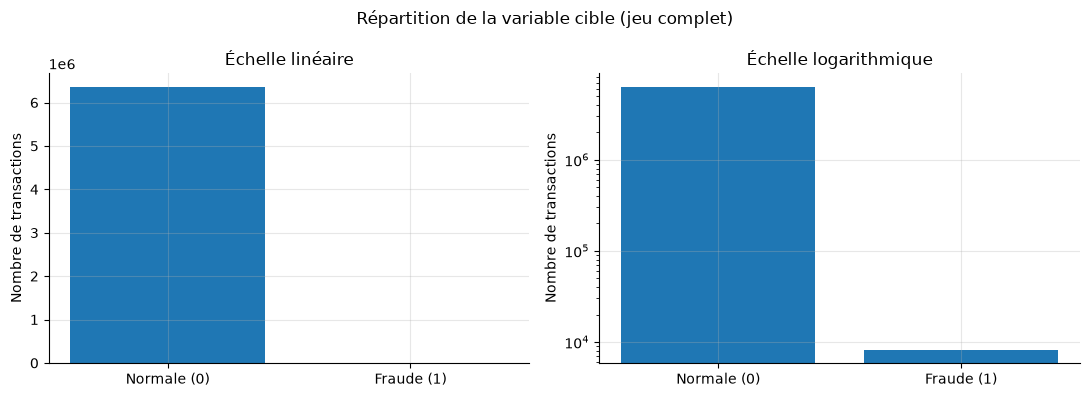

In [13]:
etiquettes = ["Normale (0)", "Fraude (1)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(etiquettes, cible["count"])
axes[0].set_title("Échelle linéaire")

axes[1].bar(etiquettes, cible["count"])
axes[1].set_yscale("log")
axes[1].set_title("Échelle logarithmique")

for ax in axes:
    ax.set_ylabel("Nombre de transactions")

fig.suptitle("Répartition de la variable cible (jeu complet)")
plt.tight_layout()
plt.show()

In [14]:
taux_fraude = cible.loc[cible["isFraud"] == 1, "count"].iloc[0] / nb_lignes
print(f"Taux de fraude : {taux_fraude:.4%}")
print(f"Accuracy d'un modèle qui prédit toujours « pas de fraude » : {1 - taux_fraude:.2%}")
print(f"Fraudes dans l'échantillon pandas : {pdf['isFraud'].sum():,}")

Taux de fraude : 0.1291%
Accuracy d'un modèle qui prédit toujours « pas de fraude » : 99.87%
Fraudes dans l'échantillon pandas : 434


In [23]:
from pyspark.sql import Window

montants = (
    df.groupBy("isFraud")
    .agg(
        F.count("*").alias("nb"),
        F.sum("amount").alias("montant_total"),
        F.avg("amount").alias("montant_moyen"),
    )
    .withColumn("pct_nb", F.col("nb") / F.sum("nb").over(Window.partitionBy()) * 100)
    .withColumn("pct_montant", F.col("montant_total") / F.sum("montant_total").over(Window.partitionBy()) * 100)
    .orderBy("isFraud")
    .toPandas()
)
montants

26/11/15 22:02:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/15 22:02:01 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/15 22:02:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/15 22:02:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/15 22:02:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/15 22:02:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


,isFraud,nb,montant_total,montant_moyen,pct_nb,pct_montant
0,0,6354407,"1,132,336,529,331.96","178,197.04",99.87,98.95
1,1,8213,"12,056,415,427.84","1,467,967.30",0.13,1.05


### 3.5 Représentativité de l'échantillon

In [25]:
comparaison_type = pd.DataFrame({
    "jeu_complet_pct": df.groupBy("type").count().toPandas()
                         .set_index("type")["count"] / nb_lignes * 100,
    "echantillon_pct": pdf["type"].value_counts(normalize=True) * 100,
})
comparaison_type

,jeu_complet_pct,echantillon_pct
type,,
CASH_IN,21.99,21.95
CASH_OUT,35.17,35.20
DEBIT,0.65,0.67
PAYMENT,33.81,33.85
TRANSFER,8.38,8.34


In [26]:
quantiles = [0.25, 0.5, 0.75, 0.99]
pd.DataFrame({
    "jeu_complet": df.approxQuantile("amount", quantiles, 0.001),
    "echantillon": pdf["amount"].quantile(quantiles).values,
}, index=quantiles)

,jeu_complet,echantillon
0.25,"13,387.92","13,329.50"
0.50,"74,687.88","74,470.17"
0.75,"208,272.94","208,054.79"
0.99,"1,581,193.46","1,605,096.32"


### Constats – partie 3
- **Déséquilibre extrême :** 8 213 fraudes sur 6 362 620 transactions (0,13 %), soit environ 1 transaction sur 775.
- **Accuracy inutilisable :** un modèle qui répond toujours « pas de fraude » aurait 99,87 % d'accuracy sans détecter une seule fraude → évaluer le modèle avec le rappel, la précision, la PR-AUC et le coût métier (semaine 5).
- **Entraînement :** avec si peu d'exemples de fraude, le modèle risque d'ignorer la classe minoritaire → compenser le déséquilibre en semaine 5 (poids des classes ou rééchantillonnage).
- **Poids en argent :** les fraudes représentent 0,13 % des transactions mais 1,05 % du montant total (12,06 milliards), avec un montant moyen 8 fois supérieur (1 467 967 contre 178 197) → chaque fraude ratée coûte cher : évaluer aussi le modèle en argent sauvé (coût métier) et prioriser les alertes à gros montant. Le montant est probablement une variable discriminante, à confirmer avec la médiane en partie 5.
- **Échantillon représentatif :** 434 fraudes sur 318 036 transactions (0,14 %, contre 0,13 % sur le jeu complet). Les parts de chaque type diffèrent de moins de 0,05 point (ex. CASH_OUT : 35,20 % contre 35,17 %) et les quartiles des montants sont presque identiques (médiane : 74 470 contre 74 688). Seul le 99e percentile s'écarte un peu (1,61 M contre 1,58 M), car les valeurs extrêmes sont rares → l'échantillon convient pour décrire l'ensemble des transactions en partie 4, mais avec prudence sur les valeurs extrêmes.
- **Mais trop peu de fraudes pour les sous-groupes :** 434 fraudes ne suffisent pas pour les étudier par type, montant ou heure → en partie 5, construire un échantillon qui garde les 8 213 fraudes (sans jamais y calculer de taux de fraude).
- **Graphiques :** la classe fraude est invisible en échelle linéaire → utiliser l'échelle logarithmique.

### 4.2 Distribution des montants
on va étudier et analyser les deux variables : type et amount

In [27]:
par_type = (
    df.groupBy("type")
    .agg(
        F.count("*").alias("nb"),
        F.sum("amount").alias("montant_total"),
        F.percentile_approx("amount", 0.5).alias("montant_median"),
    )
    .toPandas()
    .set_index("type")
    .sort_values("nb", ascending=False)
)
par_type["pct_nb"] = par_type["nb"] / par_type["nb"].sum() * 100
par_type["pct_montant"] = par_type["montant_total"] / par_type["montant_total"].sum() * 100
par_type

,nb,montant_total,montant_median,pct_nb,pct_montant
type,,,,,
CASH_OUT,2237500,"394,412,995,224.49","147,081.69",35.17,34.46
PAYMENT,2151495,"28,093,371,138.37","9,482.36",33.81,2.45
CASH_IN,1399284,"236,367,391,912.46","143,417.67",21.99,20.65
TRANSFER,532909,"485,291,987,263.17","486,293.86",8.38,42.41
DEBIT,41432,"227,199,221.28","3,048.69",0.65,0.02


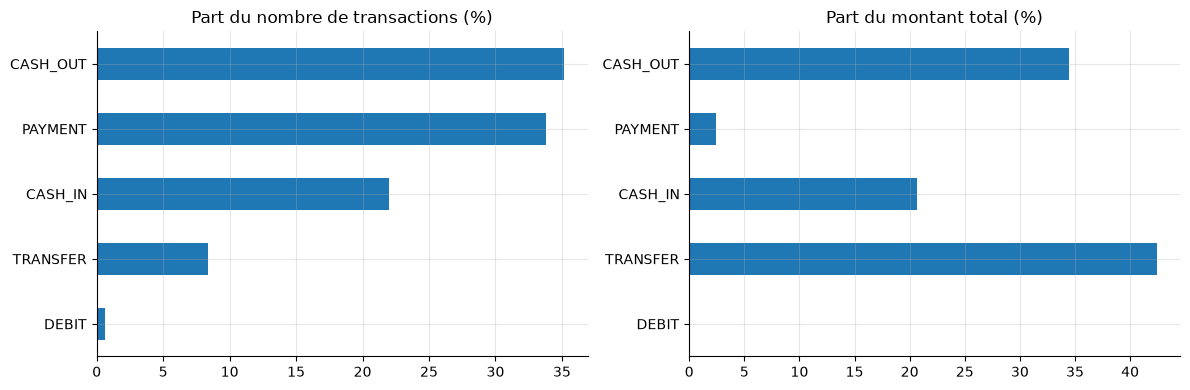

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

par_type["pct_nb"].plot.barh(ax=axes[0], title="Part du nombre de transactions (%)")
par_type["pct_montant"].plot.barh(ax=axes[1], title="Part du montant total (%)")

for ax in axes:
    ax.invert_yaxis()
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

### 4.2 Distribution des montants

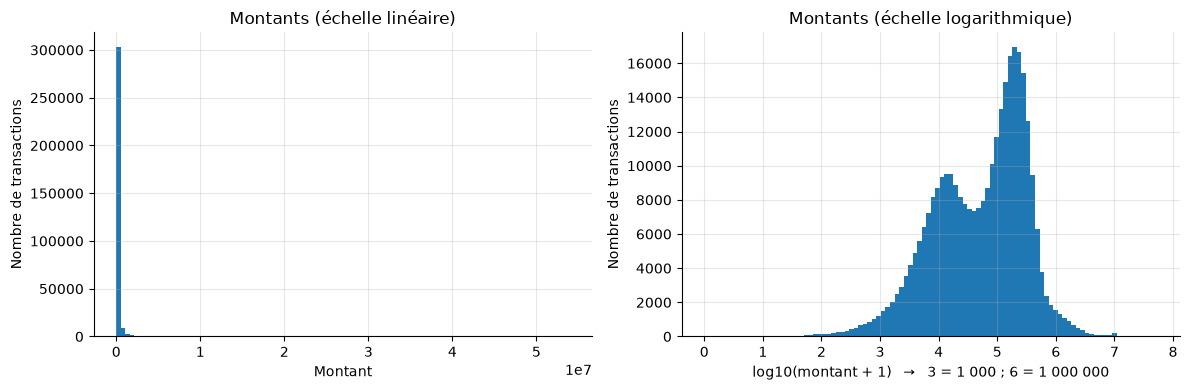

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pdf["amount"], bins=100)
axes[0].set_title("Montants (échelle linéaire)")
axes[0].set_xlabel("Montant")

axes[1].hist(np.log10(pdf["amount"] + 1), bins=100)
axes[1].set_title("Montants (échelle logarithmique)")
axes[1].set_xlabel("log10(montant + 1)   →   3 = 1 000 ; 6 = 1 000 000")

for ax in axes:
    ax.set_ylabel("Nombre de transactions")

plt.tight_layout()
plt.show()

In [30]:
print(f"Moyenne : {pdf['amount'].mean():,.0f}")
print(f"Médiane : {pdf['amount'].median():,.0f}")
print(f"Asymétrie (skewness) : {pdf['amount'].skew():.1f}")

Moyenne : 179,120
Médiane : 74,470
Asymétrie (skewness) : 28.4


/tmp/ipykernel_1020/28766930.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(np.log10(pdf["amount"] + 1), vert=False)


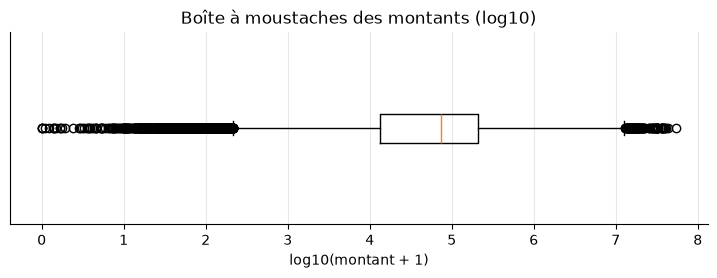

In [31]:
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.boxplot(np.log10(pdf["amount"] + 1), vert=False)
ax.set_title("Boîte à moustaches des montants (log10)")
ax.set_xlabel("log10(montant + 1)")
ax.set_yticks([])
plt.show()

In [32]:
q1, q3 = pdf["amount"].quantile([0.25, 0.75])
iqr = q3 - q1
seuil_haut = q3 + 1.5 * iqr

part_extremes = (pdf["amount"] > seuil_haut).mean() * 100
print(f"Q1 = {q1:,.0f}  |  Q3 = {q3:,.0f}  |  IQR = {iqr:,.0f}")
print(f"Seuil des valeurs extrêmes : {seuil_haut:,.0f}")
print(f"Part des transactions au-dessus du seuil : {part_extremes:.1f} %")

Q1 = 13,330  |  Q3 = 208,055  |  IQR = 194,725
Seuil des valeurs extrêmes : 500,143
Part des transactions au-dessus du seuil : 5.3 %
